# 01 — PolarGrid AI: Exploratory Data Analysis (EDA)
**SIH 2026 • Problem Statement 26061: AI-Driven Smart Energy Management System for Polar Research Stations**

This notebook inspects the real Antarctic meteorological datasets and historical reference data:
1. **ERA5 Reanalysis** (2012–2025 hourly at Maitri coordinates: $70.75^\circ\text{S}, 11.75^\circ\text{E}$)
2. **NCPOR Maitri AWS** ground truth observations (2012–2016)
3. **Australian Antarctic Reference Energy Records** (Electricity & Fuel monthly usage)


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure project path
PROJECT_ROOT = Path('.').resolve().parent if Path('.').resolve().name == 'notebooks' else Path('.').resolve()
sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)


Project root: C:\Users\ankit\Desktop\PolarGrid_AI


## 1. Load and Inspect Raw ERA5 Reanalysis Weather Data


In [2]:
era5_path = PROJECT_ROOT / "data" / "raw" / "ERA5" / "ERA5_raw_original.csv"
df_era5 = pd.read_csv(era5_path, nrows=5000)
print(f"ERA5 Sample Shape: {df_era5.shape}")
df_era5.head()


ERA5 Sample Shape: (5000, 12)


,valid_time,u10,v10,d2m,t2m,sp,ssrd,strd,tcc,tp,latitude,longitude
0,2012-01-01 00:00:00,-8.101105,4.208939,263.52040,269.37012,95845.75,160064.0,785531.00,0.575195,0.000000e+00,-70.75,11.75
1,2012-01-01 01:00:00,-8.152420,4.641830,263.09344,269.29050,95804.94,203136.0,785716.80,0.577118,0.000000e+00,-70.75,11.75
2,2012-01-01 02:00:00,-8.204605,4.844925,262.88538,269.35120,95791.89,298944.0,813338.25,0.752594,4.768372e-07,-70.75,11.75
3,2012-01-01 03:00:00,-8.163910,5.023605,262.43970,269.54636,95716.86,467968.0,813292.44,0.782257,4.768372e-07,-70.75,11.75
4,2012-01-01 04:00:00,-8.018738,5.141678,261.97427,269.66980,95699.08,710208.0,804593.30,0.924377,0.000000e+00,-70.75,11.75


In [3]:
# Summary statistics of raw meteorological variables
df_era5.describe().T


,count,mean,std,min,25%,50%,75%,max
u10,5000.0,-5.233623,4.732626,-22.567047,-8.331074,-4.339035,-1.218929,2.930191e+00
v10,5000.0,3.945929,1.700946,-1.061691,2.663509,4.072441,5.105152,8.789078e+00
d2m,5000.0,251.782320,8.501596,230.604390,244.999110,252.166610,258.793923,2.707455e+02
t2m,5000.0,259.702672,7.464144,239.978730,254.391315,260.300170,265.928975,2.736271e+02
sp,5000.0,95108.590677,898.623567,92594.266000,94552.795000,95093.452500,95700.265000,9.767078e+04
ssrd,5000.0,365326.617600,679511.536856,0.000000,0.000000,0.000000,408384.000000,2.975744e+06
strd,5000.0,665123.213994,162704.667941,361527.120000,535117.400000,648384.500000,787404.550000,1.054679e+06
tcc,5000.0,0.519962,0.448838,0.000000,0.000000,0.584564,1.000000,1.000000e+00
tp,5000.0,0.000041,0.000138,0.000000,0.000000,0.000000,0.000010,1.933098e-03
latitude,5000.0,-70.750000,0.000000,-70.750000,-70.750000,-70.750000,-70.750000,-7.075000e+01


## 2. Load NCPOR Maitri AWS Ground Truth Data


In [4]:
ncpor_path = PROJECT_ROOT / "data" / "raw" / "NCPOR_Maitri" / "NCPOR_Maitri_AWS_raw_combined.csv"
df_ncpor = pd.read_csv(ncpor_path, nrows=5000)
print(f"NCPOR AWS Sample Shape: {df_ncpor.shape}")
df_ncpor.head()


NCPOR AWS Sample Shape: (5000, 6)


,obstime,tempr,ap,ws,wd,rh
0,2012-01-01 00:00:00,-0.6,994.0,20.5,-999,-999
1,2012-01-01 01:00:00,-0.5,993.6,20.7,-999,-999
2,2012-01-01 02:00:00,-1.0,993.3,26.1,-999,-999
3,2012-01-01 03:00:00,0.0,993.0,19.2,-999,-999
4,2012-01-01 04:00:00,0.0,992.8,26.7,-999,-999


## 3. Weather Distributions and Seasonal Trends at Maitri Station


C:\Users\ankit\AppData\Local\Temp\ipykernel_11840\4025368753.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='month', y='temperature', data=df_master, ax=axes[1, 1], palette='coolwarm')


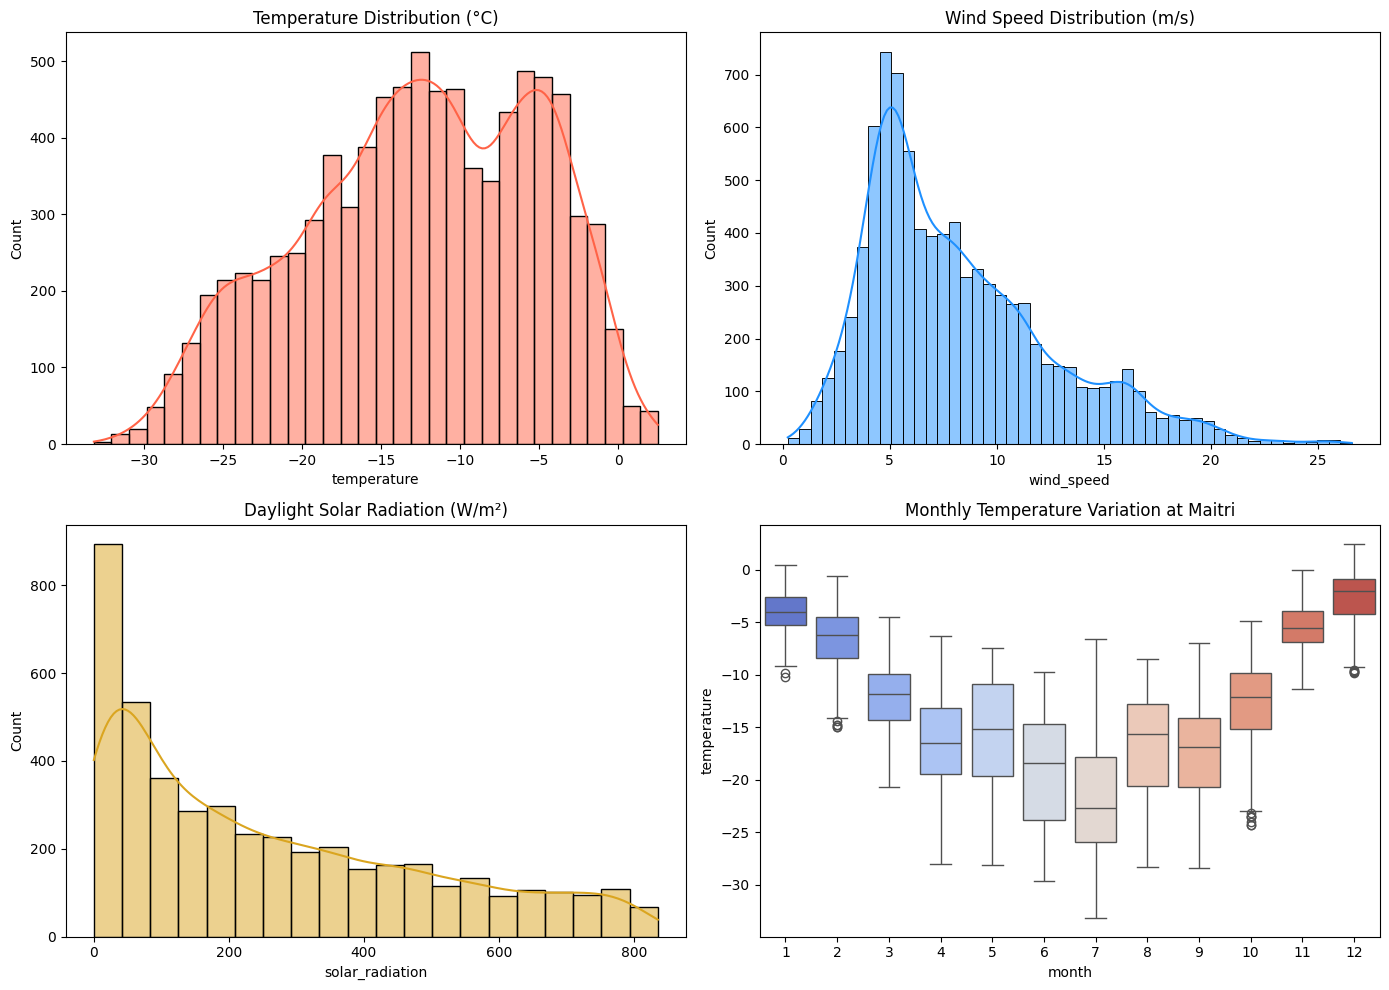

In [5]:
# Load clean processed dataset for visualization
master_path = PROJECT_ROOT / "data" / "processed" / "master_dataset.csv"
df_master = pd.read_csv(master_path, nrows=8760) # 1 full year sample

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.histplot(df_master['temperature'], kde=True, ax=axes[0, 0], color='tomato')
axes[0, 0].set_title("Temperature Distribution (°C)")

sns.histplot(df_master['wind_speed'], kde=True, ax=axes[0, 1], color='dodgerblue')
axes[0, 1].set_title("Wind Speed Distribution (m/s)")

sns.histplot(df_master[df_master['solar_radiation'] > 0]['solar_radiation'], kde=True, ax=axes[1, 0], color='goldenrod')
axes[1, 0].set_title("Daylight Solar Radiation (W/m²)")

sns.boxplot(x='month', y='temperature', data=df_master, ax=axes[1, 1], palette='coolwarm')
axes[1, 1].set_title("Monthly Temperature Variation at Maitri")
plt.tight_layout()
plt.show()
